# Simple Linear Regression on California Housing Data

This notebook fits a simple linear regression model using real California housing data. It uses **Median Income (`MedInc`)** as the single predictor and **Median House Value (`MedHouseVal`)** as the target.

The notebook covers:
- Loading and exploring real data
- Splitting data into training and testing sets
- Fitting a simple linear regression model
- Evaluating the model with RMSE and R²
- Plotting the regression line
- Calculating and plotting residuals
- Interpreting the intercept and coefficient
- Discussing model limitations

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## 2. Load the Real Dataset

In [18]:
# Load the California Housing dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 3. Select Feature and Target

For simple linear regression, only one predictor is used.

- **Feature:** `MedInc` - median income in the area, measured in tens of thousands of dollars.
- **Target:** `MedHouseVal` - median house value, measured in hundreds of thousands of dollars.

In [19]:
X = df[["MedInc"]]
y = df["MedHouseVal"]

print("Feature:")
display(X.head())

print("Target:")
display(y.head())

Feature:


,MedInc
0,8.3252
1,8.3014
2,7.2574
3,5.6431
4,3.8462


Target:


0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64

## 4. Split the Data

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

Training samples: 16512
Testing samples: 4128


## 5. Fit the Simple Linear Regression Model

In [21]:
model = LinearRegression()
model.fit(X_train, y_train)

intercept = model.intercept_
coefficient = model.coef_[0]

print(f"Intercept: {intercept:.6f}")
print(f"Coefficient for MedInc: {coefficient:.6f}")

Intercept: 0.444597
Coefficient for MedInc: 0.419338


## 6. Make Predictions and Evaluate the Model

In [6]:
y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"RMSE: {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

RMSE: 0.8421
R² Score: 0.4589


## 7. Plot the Regression Line

The regression line shows the linear relationship learned from the training data. The points below are the test observations.

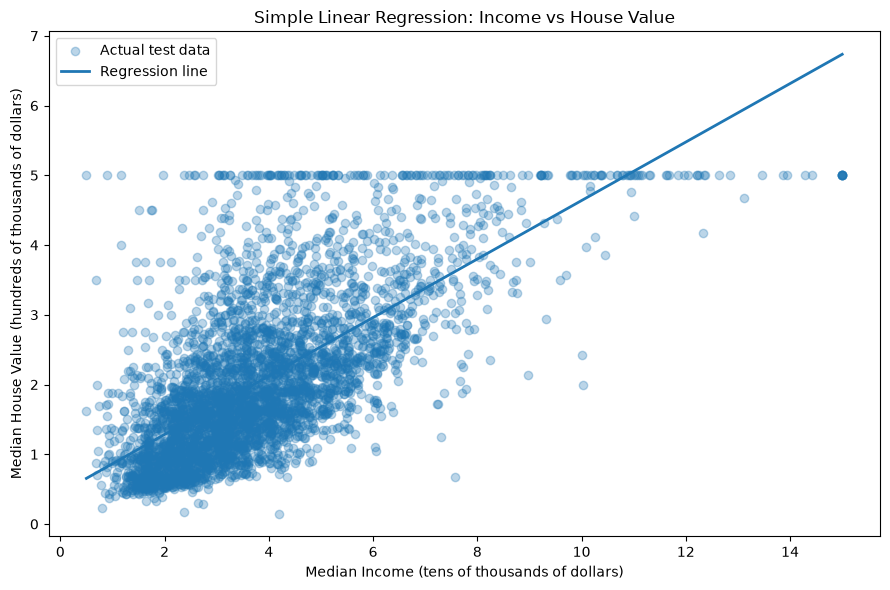

In [7]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_test["MedInc"],
    y_test,
    alpha=0.30,
    label="Actual test data"
)

x_line = np.linspace(X_test["MedInc"].min(), X_test["MedInc"].max(), 200)
y_line = model.predict(pd.DataFrame({"MedInc": x_line}))

plt.plot(x_line, y_line, linewidth=2, label="Regression line")
plt.xlabel("Median Income (tens of thousands of dollars)")
plt.ylabel("Median House Value (hundreds of thousands of dollars)")
plt.title("Simple Linear Regression: Income vs House Value")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Regression equation: MedHouseVal = {intercept:.4f} + ({coefficient:.4f} × MedInc)")

print("\nCoefficient interpretation:")
if coefficient > 0:
    print(
        f"A one-unit increase in Median Income is associated with an "
        f"average increase of {coefficient:.4f} units in predicted Median House Value."
    )
else:
    print(
        f"A one-unit increase in Median Income is associated with an "
        f"average decrease of {abs(coefficient):.4f} units in predicted Median House Value."
    )

print("\nIntercept interpretation:")
print(
    f"When Median Income is zero, the model predicts a Median House Value of "
    f"{intercept:.4f} units. This has limited practical meaning because zero "
    f"median income is not representative of the observed data."
)

In [8]:
residuals = y_test - y_pred

residual_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Residual": residuals.values
})

residual_df.head(10)

,Actual,Predicted,Residual
0,0.47700,1.149589,-0.672589
1,0.45800,1.506069,-1.048069
2,5.00001,1.903937,3.096073
3,2.18600,2.850594,-0.664594
4,2.78000,2.006633,0.773367
5,1.58700,2.421652,-0.834652
6,1.98200,2.576472,-0.594472
7,1.57500,1.992292,-0.417292
8,3.40000,2.458932,0.941068
9,4.46600,3.846774,0.619226


## 9. Residual Plot

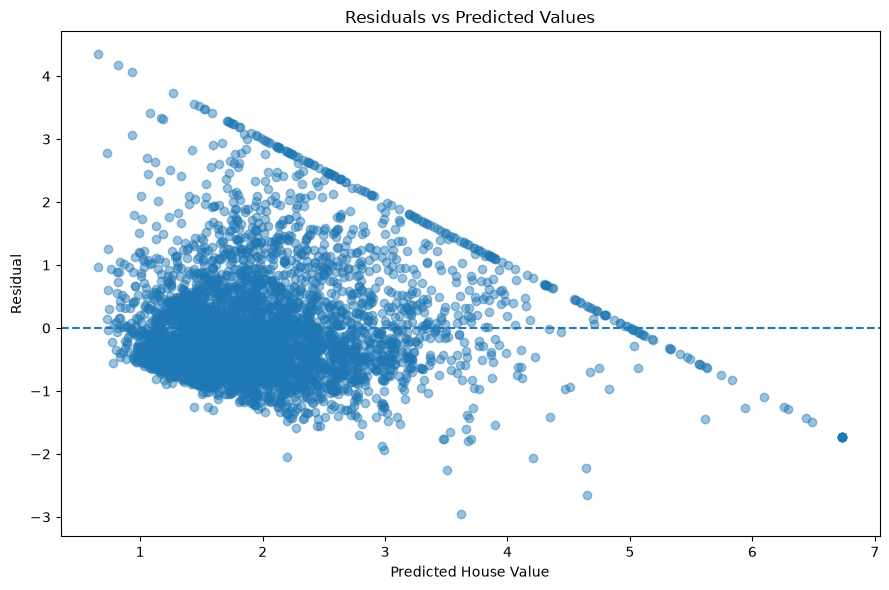

In [9]:
plt.figure(figsize=(9, 6))
plt.scatter(y_pred, residuals, alpha=0.45)
plt.axhline(y=0, linestyle="--", linewidth=1.5)
plt.xlabel("Predicted House Value")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Values")
plt.tight_layout()
plt.show()

### Residual Plot Discussion

The residuals should ideally be scattered randomly around zero without a strong curve or systematic pattern. In this model, the residuals are centered around zero but show substantial spread. This indicates that median income explains part of the variation in house values, but it does not explain all of it.

The visible variation also suggests that a simple one-feature linear model has limitations. Other variables such as location, house age, number of rooms, and population-related features can affect house value.

## 10. Residual Distribution

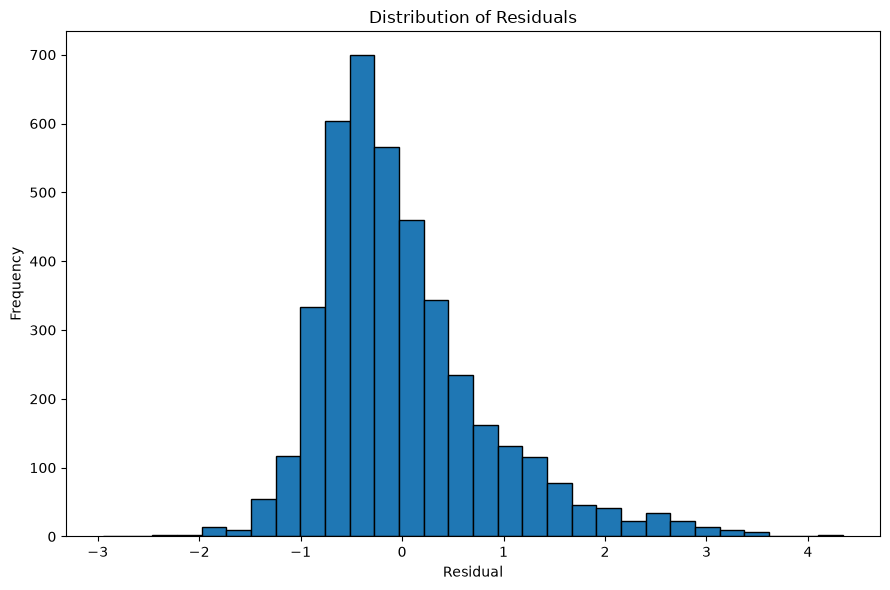

In [10]:
plt.figure(figsize=(9, 6))
plt.hist(residuals, bins=30, edgecolor="black")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.tight_layout()
plt.show()

## 11. Interpret the Coefficients

In [12]:
# Display the regression equation
print(
    f"Regression equation: "
    f"MedHouseVal = {intercept:.4f} + ({coefficient:.4f} × MedInc)"
)

# Interpret the coefficient
print("\nCoefficient interpretation:")

if coefficient > 0:
    print(
        f"A one-unit increase in Median Income is associated with an "
        f"average increase of {coefficient:.4f} units in predicted "
        f"Median House Value."
    )
else:
    print(
        f"A one-unit increase in Median Income is associated with an "
        f"average decrease of {abs(coefficient):.4f} units in predicted "
        f"Median House Value."
    )

# Interpret the intercept
print("\nIntercept interpretation:")

print(
    f"When Median Income is zero, the model predicts a Median House Value "
    f"of {intercept:.4f} units. This has limited practical meaning because "
    f"zero median income is not representative of the observed data."
)

Regression equation: MedHouseVal = 0.4446 + (0.4193 × MedInc)

Coefficient interpretation:
A one-unit increase in Median Income is associated with an average increase of 0.4193 units in predicted Median House Value.

Intercept interpretation:
When Median Income is zero, the model predicts a Median House Value of 0.4446 units. This has limited practical meaning because zero median income is not representative of the observed data.


## 12. Final Interpretation

The model shows a positive relationship between median income and median house value. The coefficient describes the expected change in predicted house value for a one-unit increase in the income feature.

The residual analysis shows that the model captures an important part of the relationship, but the errors still have substantial variation. Therefore, median income alone is not sufficient to fully explain house values.

For a more complete model, additional housing features could be included using multiple linear regression.

## 13. Conclusion

A simple linear regression model was successfully fitted on real California housing data. The notebook includes model fitting, numerical evaluation, a regression-line visualization, residual plots, residual discussion, and coefficient interpretation.

This satisfies the core requirements of the assignment while keeping the project intentionally small and focused.